# Remake -- explaining individual predictions

Pick 10 random houses, predict each one's price, and explain **why** the
model gave that price.

- **Model:** XGBoost (most accurate in `remake_train.ipynb`), same settings.
- **Honest test:** trained on fold 5's training period (sales up to January
  2026); the 10 houses are drawn at random from fold 5's **test** period
  (January -- August 2026), so the model has never seen them. Each
  prediction can be checked against the real sale price.
- **Explanation:** SHAP splits each prediction into
  `average price + one contribution per feature`. Shown as a plain-English
  summary (features grouped into themes) and a waterfall chart with
  features in real units.

Sections 1--3 are copied unchanged from `remake_train.ipynb`.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [2]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month", "sale_quarter",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET}
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

29 features: 5 categorical, 1 boolean, 23 numeric


## 2. Per-fold processing (same as `remake_train.ipynb`)

In [3]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 3. Build the 5 folds

In [4]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,777


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9760,9779,450000.0,4512000.0
2,2024-11-07,2024-11-07 to 2025-04-01,19505,9685,450000.0,4229700.0
3,2025-04-01,2025-04-01 to 2025-08-22,29263,9783,430000.0,4261500.0
4,2025-08-22,2025-08-22 to 2026-01-24,39008,9761,433089.1,4219250.0
5,2026-01-24,2026-01-24 to 2026-08-18,48774,9769,430243.6,4200000.0


## 4. Train XGBoost on fold 5 and pick 10 unseen houses

In [5]:
import shap
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

fold = folds[-1]
model = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
)
model.fit(fold["X_train"], fold["y_train"])

houses = fold["X_test"].sample(n=10, random_state=7)
actual = pd.Series(fold["y_test"], index=fold["X_test"].index).loc[houses.index]
predicted = pd.Series(model.predict(houses), index=houses.index)

explainer = shap.TreeExplainer(model)
shap_values = explainer(houses)
base_value = float(shap_values.base_values[0])

# SHAP is additive: average + contributions must equal the prediction.
assert np.allclose(shap_values.values.sum(axis=1) + base_value, predicted.values, rtol=1e-4)
print(f"Model trained on {len(fold['y_train']):,} sales up to "
      f"{df.loc[fold['X_train'].index, 'sale_date_parsed'].max().date()}")
print(f"Average predicted price (SHAP starting point): ${base_value:,.0f}")

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model trained on 48,774 sales up to 2026-01-24
Average predicted price (SHAP starting point): $1,150,951


## 5. Readable values and addresses

The model's inputs include log-transformed sizes and integer category codes.
For the explanations they are converted back to real units (land and floor
area in sqm, distances in km or m, building age as a decade). Addresses come
from the original sales file.

In [6]:
raw = pd.read_parquet(
    "./cache/dvrs_with_team_external.parquet",
    columns=["valuation_id_concat", "sale_date", "sale_price_gross",
             "situation_number", "additional_situation_number", "situation_name"],
)
raw["sale_price_gross"] = pd.to_numeric(raw["sale_price_gross"], errors="coerce")
raw["sale_date_parsed"] = pd.to_datetime(raw["sale_date"].astype(str).str.zfill(8), format="%d%m%Y")
raw["address"] = (
    raw["situation_number"].astype(str)
    + raw["additional_situation_number"].fillna("").astype(str)
    + " " + raw["situation_name"].fillna("").astype(str).str.title()
)
addresses = (
    raw.drop_duplicates(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])
    .set_index(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])["address"]
)
key = pd.MultiIndex.from_frame(df.loc[houses.index, ["valuation_id_concat", "sale_date_parsed", "sale_price_gross"]])
house_address = pd.Series(addresses.reindex(key).values, index=houses.index).fillna("(address not found)")


def readable_row(i):
    """Feature values for one house in human units (from the unprocessed data)."""
    r = df.loc[i]
    age = str(r["building_age_indicator"])
    return {
        "property_type": r["property_type"],
        "building_age_indicator": f"{age}0s" if age.isdigit() else age,
        "building_condition_indicator": r["building_condition_indicator"],
        "building_construction_indicator": r["building_construction_indicator"],
        "noise_category_combination": r["noise_category_combination"].replace("_", " "),
        "in_flood_plain": "yes" if r["in_flood_plain"] else "no",
        "land_area": f"{np.expm1(r['land_area']) * 10_000:,.0f} sqm",  # stored in hectares
        "building_total_floor_area": f"{np.expm1(r['building_total_floor_area']):,.0f} sqm",
        "mass_total_floor_area": f"{np.expm1(r['mass_total_floor_area']):,.0f} sqm",
        "off_street_parking": f"{r['off_street_parking']:.0f}",
        "mass_garage_under_main_roof": f"{r['mass_garage_under_main_roof']:.0f}",
        "mass_garage_freestanding": f"{r['mass_garage_freestanding']:.0f}",
        "latitude": f"{r['latitude']:.4f}",
        "longitude": f"{r['longitude']:.4f}",
        "distance_to_cbd": f"{r['distance_to_cbd'] / 1000:.1f} km",
        "walk_supermarket_network_m": "n/a" if pd.isna(r["walk_supermarket_network_m"]) else f"{np.expm1(r['walk_supermarket_network_m']):,.0f} m",
        "walk_bus_stop_network_m": "n/a" if pd.isna(r["walk_bus_stop_network_m"]) else f"{np.expm1(r['walk_bus_stop_network_m']):,.0f} m",
        "distance_to_school": f"{r['distance_to_school']:,.0f} m",
        "area_level_deprivation_index": f"{r['area_level_deprivation_index']:.0f} of 10",
        "median_personal_income_by_sa": f"${r['median_personal_income_by_sa']:,.0f}",
        "employment_rate_by_sa": f"{r['employment_rate_by_sa']:.0f}%",
        "unemployment_rate_by_sa": f"{r['unemployment_rate_by_sa']:.1f}%",
        "population_counts_by_sa": f"{r['population_counts_by_sa']:,.0f}",
        "population_density": f"{r['population_density']:,.0f} per sq km",
        "distance_to_coastline": f"{r['distance_to_coastline']:,.0f} m",
        "building_consents": f"{r['building_consents']:.0f}",
        "sale_year": f"{r['sale_year']:.0f}",
        "sale_month": f"{r['sale_month']:.0f}",
        "sale_quarter": f"Q{r['sale_quarter']:.0f}",
    }


readable = pd.DataFrame([readable_row(i) for i in houses.index], index=houses.index)[FEATURE_COLS]

## 6. The 10 houses at a glance

In [7]:
summary = pd.DataFrame({
    "address": house_address,
    "sale_date": df.loc[houses.index, "sale_date_parsed"].dt.date,
    "actual_price": actual.map("${:,.0f}".format),
    "predicted_price": predicted.map("${:,.0f}".format),
    "error": ((predicted - actual) / actual * 100).map("{:+.1f}%".format),
})
summary.index = range(1, len(summary) + 1)
summary.index.name = "house"
summary

,address,sale_date,actual_price,predicted_price,error
house,,,,,
1,119 Waimumu Rd,2026-05-15,"$1,085,000","$959,834",-11.5%
2,8/3 Park Rise,2026-05-20,"$1,495,000","$1,530,707",+2.4%
3,40E Estuary Rd,2026-02-02,"$690,000","$687,840",-0.3%
4,15A Clifton Rd,2026-05-06,"$2,755,000","$3,184,152",+15.6%
5,182 Glamorgan Dr,2026-04-24,"$835,000","$1,108,409",+32.7%
6,3 Uma Gr,2026-04-15,"$765,000","$806,377",+5.4%
7,12B Rewi St,2026-06-01,"$1,285,000","$1,261,136",-1.9%
8,10 Pecan Pl,2026-02-19,"$835,000","$939,700",+12.5%
9,10 Wairua Pl,2026-06-21,"$680,000","$683,442",+0.5%


## 7. Why the model gave each price

Contributions are grouped into five themes for the summary. Because SHAP
values add up, a theme's contribution is simply the sum of its features'
contributions. The waterfall chart below each summary shows the individual
features (the 10 largest; the rest are combined into one bar).

These explain what the **model** learned from past sales -- they are not
proof that a feature causes a price change in the market.

House 1: 119 Waimumu Rd  (sold 2026-05-15)
  Predicted $959,834   actual $1,085,000   error -11.5%
  Start from the average predicted price: $1,150,951
       -$152,261  Location         mainly longitude = 174.6163 (-$143,967), latitude = -36.8456 (+$54,189)
       -$112,536  Neighbourhood    mainly area_level_deprivation_index = 9 of 10 (-$91,000), unemployment_rate_by_sa = 7.2% (-$16,803)
        +$77,240  House & land     mainly land_area = 1,158 sqm (+$151,851), building_age_indicator = 1960s (-$42,254)
         -$5,504  Market & timing  mainly sale_year = 2026 (-$10,027), building_consents = 46 (+$7,577)
         +$1,945  Hazards          mainly in_flood_plain = no (+$1,987), noise_category_combination = outside current overlay (-$42)
  = predicted $959,834
  In short: the biggest push UP is land_area (1,158 sqm, +$151,851); the biggest push DOWN is longitude (174.6163, -$143,967).


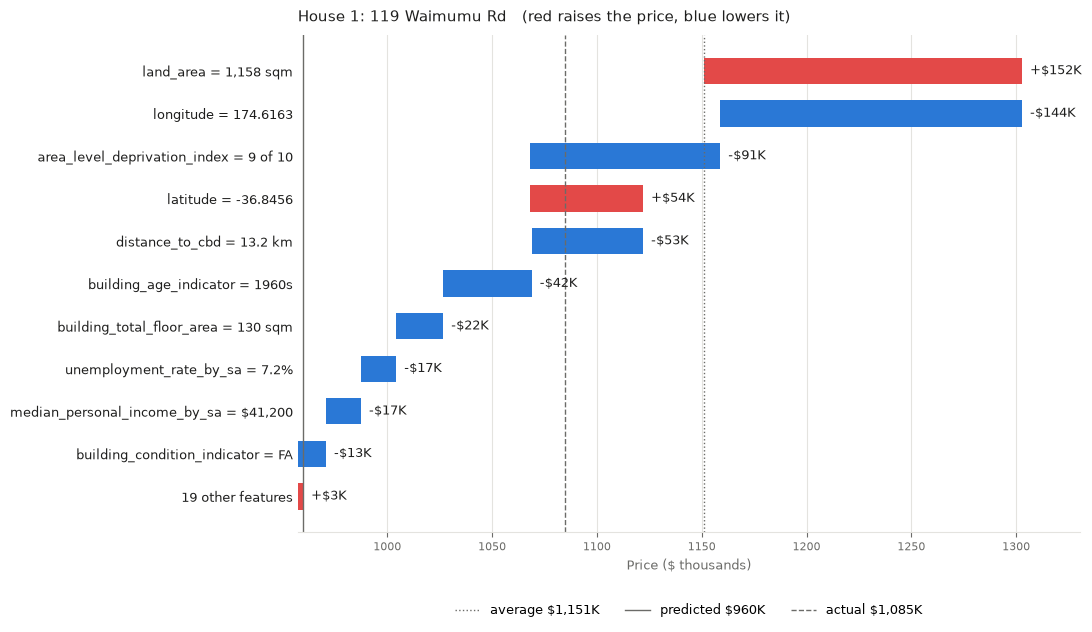


House 2: 8/3 Park Rise  (sold 2026-05-20)
  Predicted $1,530,707   actual $1,495,000   error +2.4%
  Start from the average predicted price: $1,150,951
       +$278,948  Location         mainly latitude = -36.7478 (+$148,823), longitude = 174.7608 (+$73,397)
       +$150,305  Neighbourhood    mainly area_level_deprivation_index = 1 of 10 (+$104,464), median_personal_income_by_sa = $54,200 (+$28,820)
        -$31,829  House & land     mainly land_area = 200 sqm (-$88,535), building_age_indicator = 2020s (+$32,880)
        -$19,474  Market & timing  mainly sale_year = 2026 (-$17,710), sale_month = 5 (-$4,409)
         +$1,807  Hazards          mainly in_flood_plain = no (+$1,974), noise_category_combination = outside current overlay (-$167)
  = predicted $1,530,707
  In short: the biggest push UP is latitude (-36.7478, +$148,823); the biggest push DOWN is land_area (200 sqm, -$88,535).


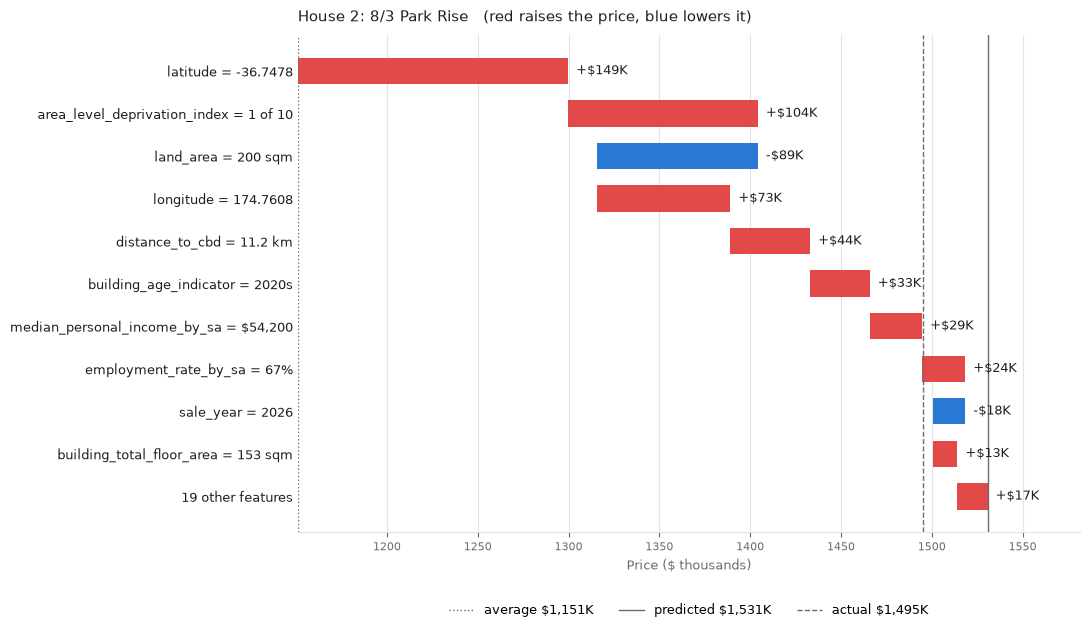


House 3: 40E Estuary Rd  (sold 2026-02-02)
  Predicted $687,840   actual $690,000   error -0.3%
  Start from the average predicted price: $1,150,951
       -$237,308  House & land     mainly land_area = 108 sqm (-$109,374), mass_total_floor_area = 100 sqm (-$97,686)
       -$131,228  Location         mainly latitude = -37.0469 (-$109,470), distance_to_cbd = 23.9 km (-$108,490)
        -$83,670  Neighbourhood    mainly area_level_deprivation_index = 10 of 10 (-$63,642), unemployment_rate_by_sa = 7.6% (-$19,893)
        -$11,806  Market & timing  mainly sale_year = 2026 (-$25,307), sale_month = 2 (+$11,393)
           +$902  Hazards          mainly in_flood_plain = no (+$983), noise_category_combination = outside current overlay (-$81)
  = predicted $687,840
  In short: the biggest push UP is distance_to_coastline (48 m, +$47,026); the biggest push DOWN is latitude (-37.0469, -$109,470).


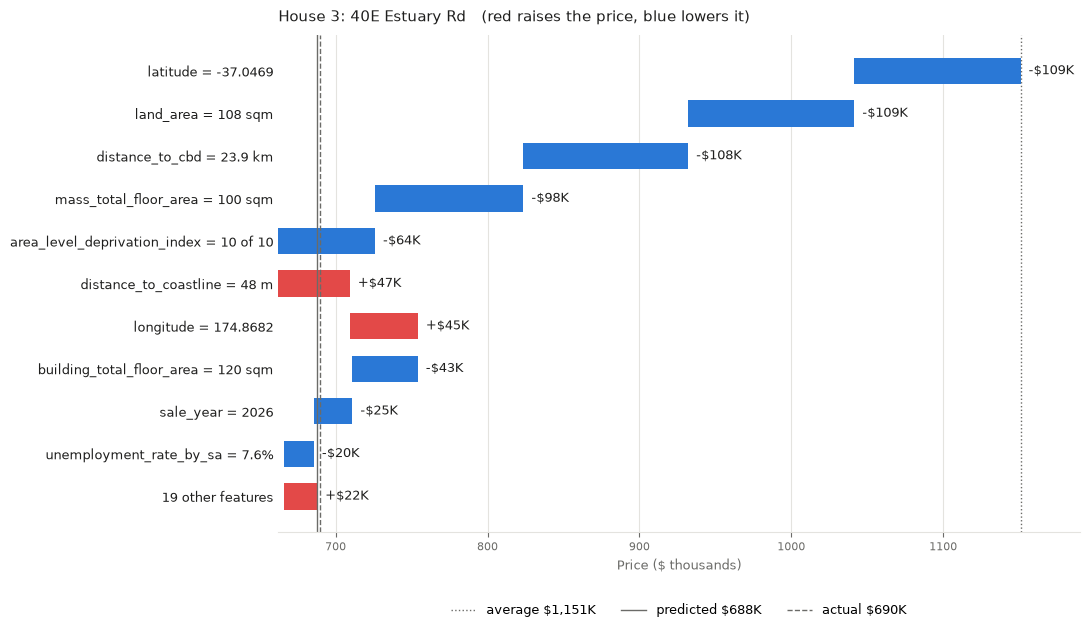


House 4: 15A Clifton Rd  (sold 2026-05-06)
  Predicted $3,184,152   actual $2,755,000   error +15.6%
  Start from the average predicted price: $1,150,951
       +$972,390  Location         mainly distance_to_cbd = 2.9 km (+$883,850), latitude = -36.8465 (+$123,029)
       +$807,539  House & land     mainly mass_total_floor_area = 234 sqm (+$445,713), building_total_floor_area = 271 sqm (+$308,334)
       +$302,489  Neighbourhood    mainly median_personal_income_by_sa = $70,200 (+$225,737), area_level_deprivation_index = 1 of 10 (+$69,474)
        -$52,770  Market & timing  mainly sale_year = 2026 (-$63,732), sale_quarter = Q2 (+$4,961)
         +$3,552  Hazards          mainly in_flood_plain = no (+$3,601), noise_category_combination = outside current overlay (-$49)
  = predicted $3,184,152
  In short: the biggest push UP is distance_to_cbd (2.9 km, +$883,850); the biggest push DOWN is building_age_indicator (1980s, -$106,425).


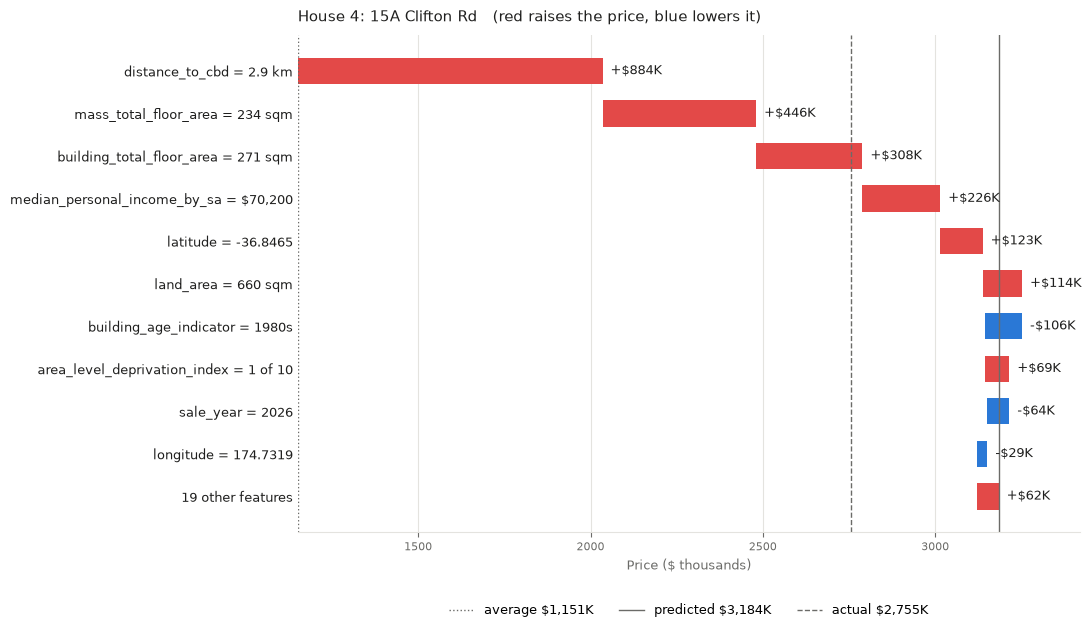


House 5: 182 Glamorgan Dr  (sold 2026-04-24)
  Predicted $1,108,409   actual $835,000   error +32.7%
  Start from the average predicted price: $1,150,951
       -$148,709  House & land     mainly land_area = 0 sqm (-$107,014), building_age_indicator = 1970s (-$68,831)
       +$140,330  Location         mainly distance_to_coastline = 20 m (+$117,657), latitude = -36.7011 (+$116,205)
        -$30,816  Market & timing  mainly sale_year = 2026 (-$16,995), sale_month = 4 (-$8,689)
         -$5,180  Neighbourhood    mainly employment_rate_by_sa = 72% (-$42,671), unemployment_rate_by_sa = 2.4% (+$41,046)
         +$1,832  Hazards          mainly in_flood_plain = no (+$2,077), noise_category_combination = outside current overlay (-$245)
  = predicted $1,108,409
  In short: the biggest push UP is distance_to_coastline (20 m, +$117,657); the biggest push DOWN is land_area (0 sqm, -$107,014).


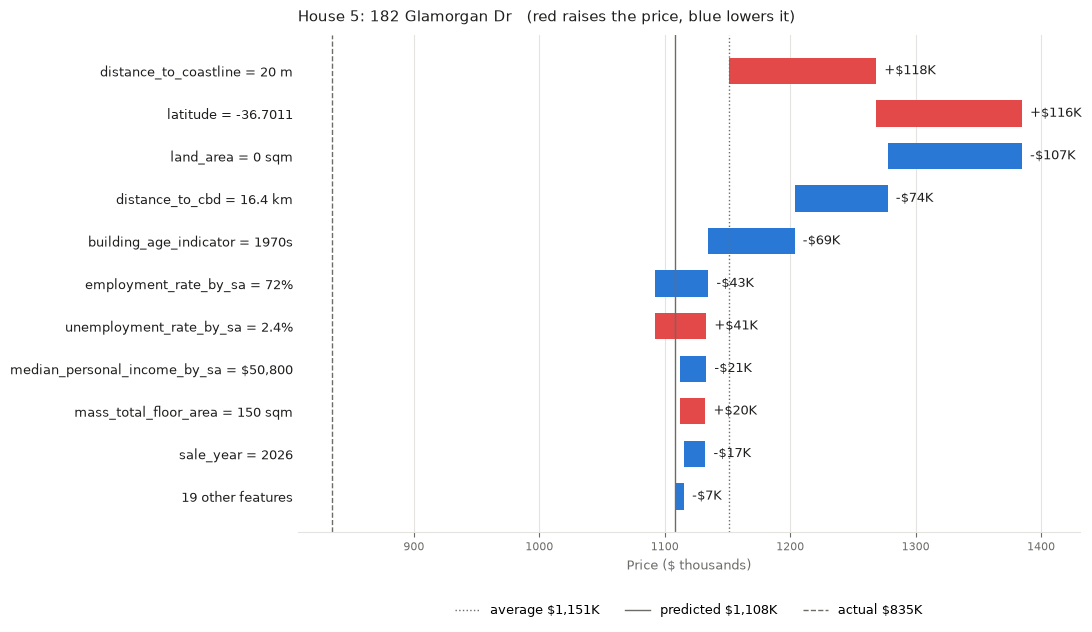


House 6: 3 Uma Gr  (sold 2026-04-15)
  Predicted $806,377   actual $765,000   error +5.4%
  Start from the average predicted price: $1,150,951
       -$326,153  House & land     mainly land_area = 105 sqm (-$153,155), mass_total_floor_area = 92 sqm (-$104,713)
       +$100,978  Neighbourhood    mainly area_level_deprivation_index = 1 of 10 (+$64,273), median_personal_income_by_sa = $65,000 (+$58,245)
        -$96,479  Location         mainly longitude = 174.6516 (-$79,746), walk_supermarket_network_m = 463 m (-$14,106)
        -$24,862  Market & timing  mainly sale_year = 2026 (-$18,652), building_consents = 5 (-$4,440)
         +$1,942  Hazards          mainly in_flood_plain = no (+$2,359), noise_category_combination = outside current overlay (-$417)
  = predicted $806,377
  In short: the biggest push UP is area_level_deprivation_index (1 of 10, +$64,273); the biggest push DOWN is land_area (105 sqm, -$153,155).


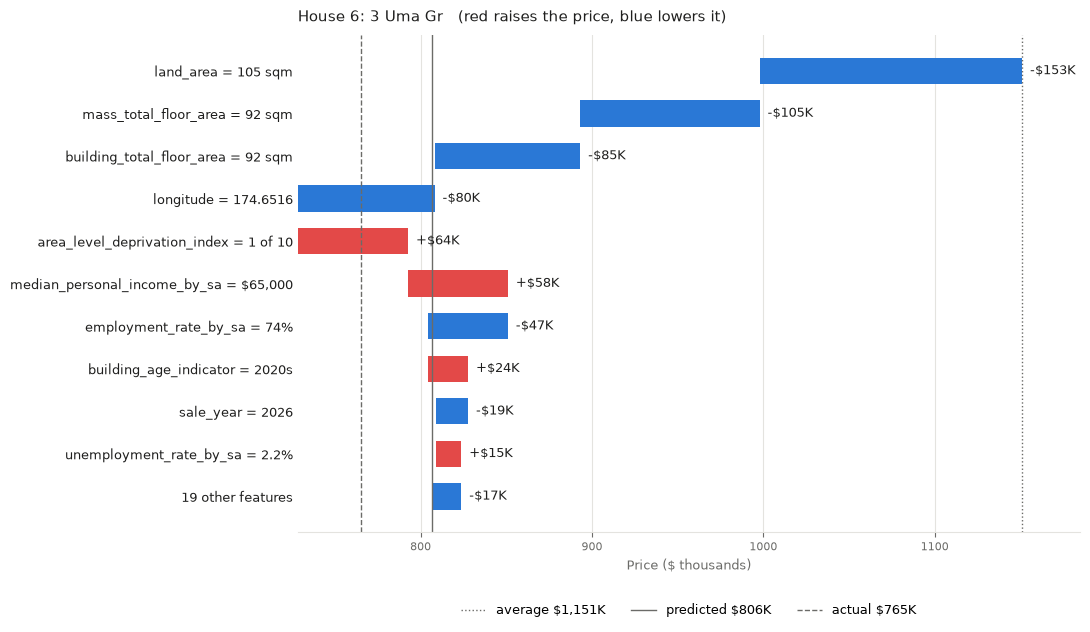


House 7: 12B Rewi St  (sold 2026-06-01)
  Predicted $1,261,136   actual $1,285,000   error -1.9%
  Start from the average predicted price: $1,150,951
        +$57,187  Location         mainly latitude = -36.6966 (+$97,211), distance_to_cbd = 16.9 km (-$74,197)
        +$41,540  House & land     mainly land_area = 186 sqm (-$99,610), mass_total_floor_area = 154 sqm (+$56,455)
        +$28,244  Neighbourhood    mainly area_level_deprivation_index = 2 of 10 (+$45,300), median_personal_income_by_sa = $49,800 (-$9,386)
        -$18,758  Market & timing  mainly sale_year = 2026 (-$11,877), sale_month = 6 (-$7,932)
         +$1,972  Hazards          mainly in_flood_plain = no (+$2,093), noise_category_combination = outside current overlay (-$121)
  = predicted $1,261,136
  In short: the biggest push UP is latitude (-36.6966, +$97,211); the biggest push DOWN is land_area (186 sqm, -$99,610).


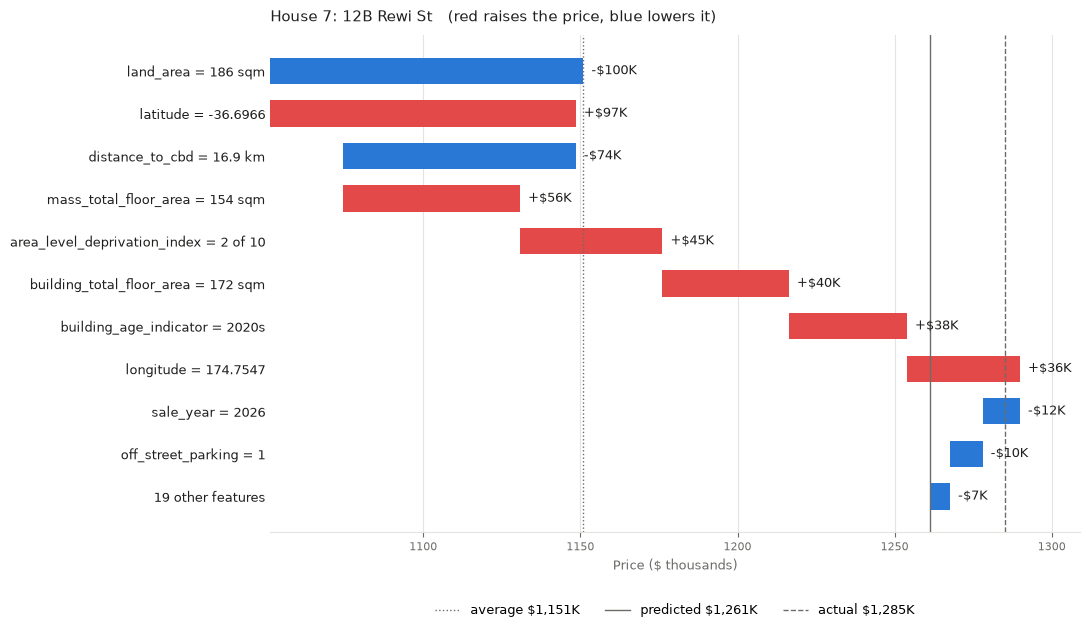


House 8: 10 Pecan Pl  (sold 2026-02-19)
  Predicted $939,700   actual $835,000   error +12.5%
  Start from the average predicted price: $1,150,951
        -$94,012  Neighbourhood    mainly area_level_deprivation_index = 8 of 10 (-$84,766), employment_rate_by_sa = 63% (+$16,254)
        -$90,181  House & land     mainly land_area = 0 sqm (-$121,888), building_age_indicator = 2000s (-$36,414)
        -$19,896  Location         mainly longitude = 174.6912 (-$45,370), distance_to_cbd = 8.7 km (+$17,898)
         -$8,712  Market & timing  mainly sale_year = 2026 (-$22,190), sale_month = 2 (+$10,667)
         +$1,552  Hazards          mainly in_flood_plain = no (+$1,615), noise_category_combination = outside current overlay (-$63)
  = predicted $939,700
  In short: the biggest push UP is building_total_floor_area (172 sqm, +$35,140); the biggest push DOWN is land_area (0 sqm, -$121,888).


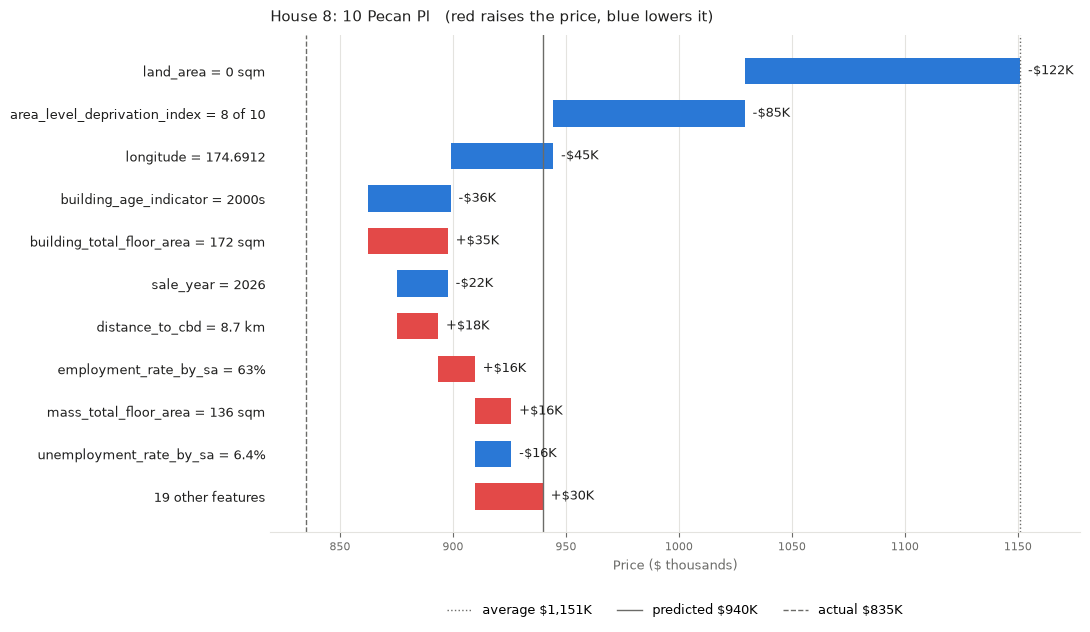


House 9: 10 Wairua Pl  (sold 2026-06-21)
  Predicted $683,442   actual $680,000   error +0.5%
  Start from the average predicted price: $1,150,951
       -$247,160  Location         mainly distance_to_cbd = 40.1 km (-$173,741), latitude = -37.1965 (-$126,317)
       -$127,721  House & land     mainly building_construction_indicator = RI (-$50,635), building_age_indicator = 1990s (-$35,809)
        -$77,615  Neighbourhood    mainly area_level_deprivation_index = 10 of 10 (-$67,641), median_personal_income_by_sa = $39,000 (-$14,767)
        -$16,074  Market & timing  mainly sale_year = 2026 (-$9,300), sale_month = 6 (-$8,765)
         +$1,062  Hazards          mainly in_flood_plain = no (+$1,104), noise_category_combination = outside current overlay (-$42)
  = predicted $683,442
  In short: the biggest push UP is longitude (174.8879, +$55,381); the biggest push DOWN is distance_to_cbd (40.1 km, -$173,741).


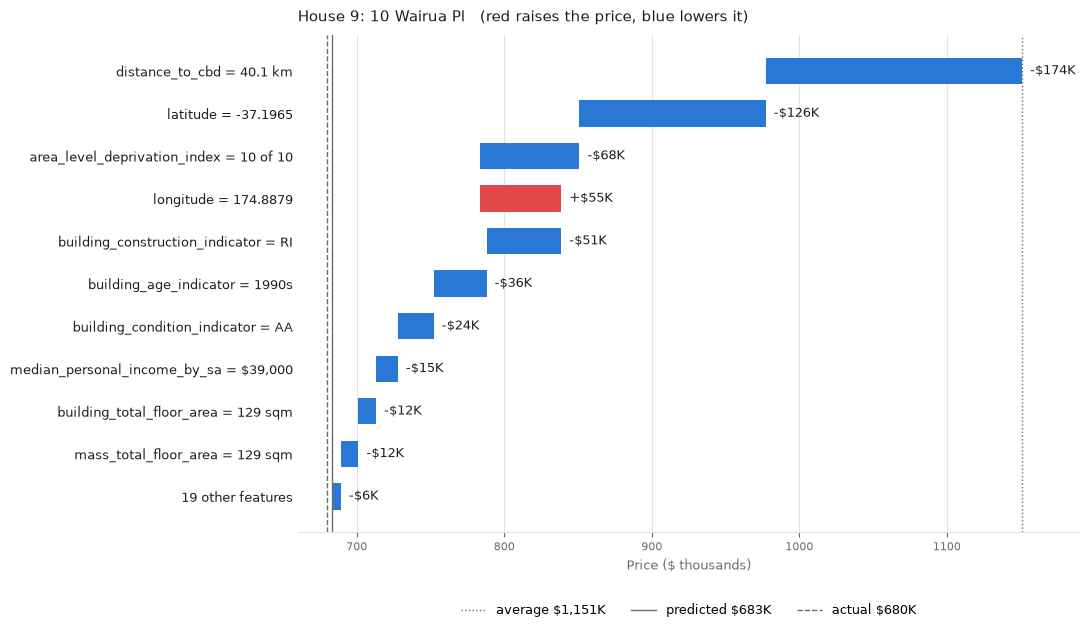


House 10: 57 Castlefinn Dr  (sold 2026-02-23)
  Predicted $801,892   actual $911,000   error -12.0%
  Start from the average predicted price: $1,150,951
       -$172,936  Location         mainly distance_to_cbd = 22.9 km (-$128,108), latitude = -37.0359 (-$99,194)
        -$80,734  Neighbourhood    mainly area_level_deprivation_index = 10 of 10 (-$67,841), employment_rate_by_sa = 56% (+$26,081)
        -$75,219  House & land     mainly mass_total_floor_area = 101 sqm (-$84,350), building_age_indicator = 2000s (-$21,647)
        -$21,031  Market & timing  mainly sale_year = 2026 (-$21,492), building_consents = 0 (-$9,143)
           +$861  Hazards          mainly in_flood_plain = no (+$946), noise_category_combination = outside current overlay (-$85)
  = predicted $801,892
  In short: the biggest push UP is longitude (174.8724, +$44,734); the biggest push DOWN is distance_to_cbd (22.9 km, -$128,108).


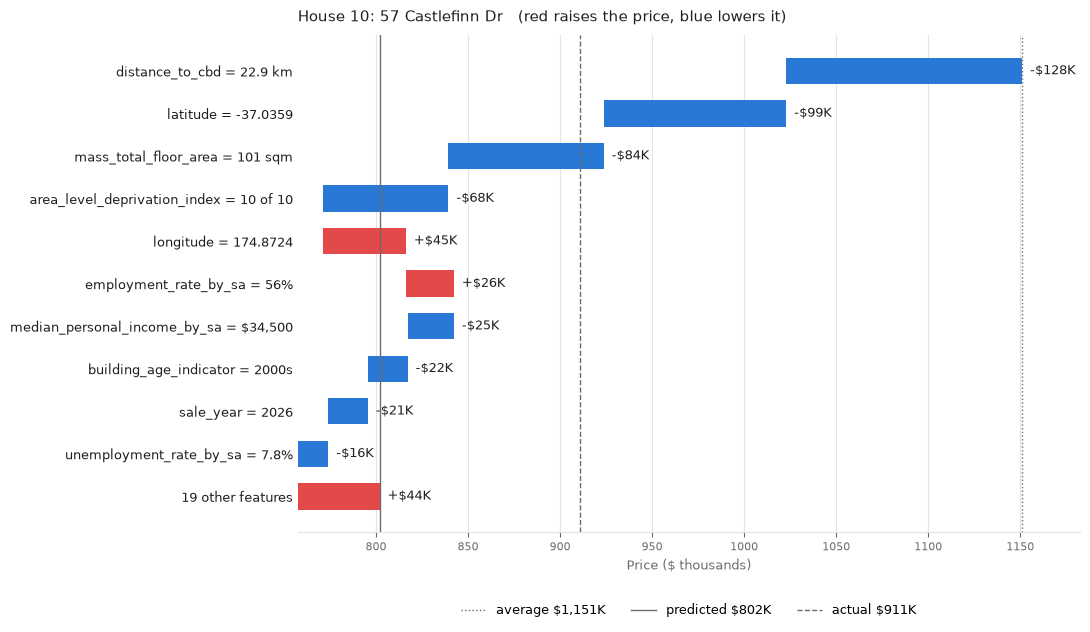

In [8]:
from matplotlib.lines import Line2D

THEMES = {
    "Location": ["latitude", "longitude", "distance_to_cbd", "distance_to_coastline",
                 "distance_to_school", "walk_supermarket_network_m", "walk_bus_stop_network_m"],
    "Neighbourhood": ["area_level_deprivation_index", "median_personal_income_by_sa",
                      "employment_rate_by_sa", "unemployment_rate_by_sa",
                      "population_counts_by_sa", "population_density"],
    "House & land": ["land_area", "building_total_floor_area", "mass_total_floor_area",
                     "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
                     "building_age_indicator", "building_condition_indicator",
                     "building_construction_indicator", "property_type"],
    "Hazards": ["in_flood_plain", "noise_category_combination"],
    "Market & timing": ["building_consents", "sale_year", "sale_month", "sale_quarter"],
}
assert sorted(sum(THEMES.values(), [])) == sorted(FEATURE_COLS), "every feature must be in exactly one theme"

UP, DOWN = "#e34948", "#2a78d6"          # raises / lowers the price
INK, INK_MUTED, GRID = "#1f1f1e", "#6b6b68", "#e4e3df"


def money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


def mpl(s):
    # A bare "$" switches matplotlib into maths formatting, so escape it.
    return s.replace("$", "\\$")


def waterfall(contrib, i, n, top_n=10):
    """Bars run from the average price to the prediction, one step per feature."""
    order = contrib.abs().sort_values(ascending=False).index
    shown = contrib[order[:top_n]]
    rest = contrib[order[top_n:]].sum()
    steps = list(shown.items()) + [(f"{len(order) - top_n} other features", rest)]
    labels = [f"{f} = {readable.loc[i, f]}" if f in readable.columns else f for f, _ in steps]

    fig, ax = plt.subplots(figsize=(11, 0.42 * len(steps) + 1.8))
    level = base_value
    for row, (_, v) in enumerate(steps):
        start, end = level, level + v
        ax.barh(row, (end - start) / 1000, left=start / 1000, height=0.62,
                color=UP if v >= 0 else DOWN)
        ax.text(max(start, end) / 1000, row, mpl(f"  {'+' if v >= 0 else '-'}${abs(v) / 1000:,.0f}K"),
                va="center", ha="left", fontsize=9, color=INK)
        level = end

    reference = [
        (base_value, f"average ${base_value / 1000:,.0f}K", ":"),
        (predicted[i], f"predicted ${predicted[i] / 1000:,.0f}K", "-"),
        (actual[i], f"actual ${actual[i] / 1000:,.0f}K", "--"),
    ]
    for value, _, style in reference:
        ax.axvline(value / 1000, color=INK_MUTED, linestyle=style, linewidth=1)
    ax.legend(
        handles=[Line2D([], [], color=INK_MUTED, linestyle=s, linewidth=1, label=mpl(t)) for _, t, s in reference],
        loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9,
    )

    ax.set_yticks(range(len(steps)))
    ax.set_yticklabels([mpl(l) for l in labels], fontsize=9, color=INK)
    ax.invert_yaxis()
    ax.set_xlabel(mpl("Price ($ thousands)"), fontsize=9, color=INK_MUTED)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", colors=INK_MUTED, labelsize=8)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    left, right = ax.get_xlim()
    ax.set_xlim(left, right + (right - left) * 0.08)  # room for the last label
    ax.set_title(f"House {n}: {house_address[i]}   (red raises the price, blue lowers it)",
                 loc="left", fontsize=11, color=INK, pad=10)
    plt.tight_layout()
    plt.show()


def explain_house(n, i):
    pos = houses.index.get_loc(i)
    contrib = pd.Series(shap_values.values[pos], index=FEATURE_COLS)
    themes = pd.Series({t: contrib[cols].sum() for t, cols in THEMES.items()})
    err = (predicted[i] - actual[i]) / actual[i] * 100

    print(f"House {n}: {house_address[i]}  (sold {df.loc[i, 'sale_date_parsed'].date()})")
    print(f"  Predicted ${predicted[i]:,.0f}   actual ${actual[i]:,.0f}   error {err:+.1f}%")
    print(f"  Start from the average predicted price: ${base_value:,.0f}")
    for theme, value in themes.sort_values(key=abs, ascending=False).items():
        top = contrib[THEMES[theme]].sort_values(key=abs, ascending=False).head(2)
        detail = ", ".join(f"{f} = {readable.loc[i, f]} ({money(v)})" for f, v in top.items())
        print(f"    {money(value):>12}  {theme:<16} mainly {detail}")
    print(f"  = predicted ${predicted[i]:,.0f}")

    up = contrib.idxmax()
    down = contrib.idxmin()
    print(f"  In short: the biggest push UP is {up} ({readable.loc[i, up]}, {money(contrib[up])}); "
          f"the biggest push DOWN is {down} ({readable.loc[i, down]}, {money(contrib[down])}).")
    waterfall(contrib, i, n)
    print()


for n, i in enumerate(houses.index, start=1):
    explain_house(n, i)